trains Linear Regression, Random Forest, and XGBoost on:

1. Non-PCA features
2. PCA features

In [65]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and paths

In [66]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.use("Agg")  # safe for notebook saving

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
    print("XGBoost imported successfully.")
except Exception as e:
    XGBOOST_AVAILABLE = False
    print("XGBoost import failed:", e)

PROJECT_DIR = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")

NO_DR_DIR  = PROJECT_DIR / "model_ready_no_dr"
PCA_DIR    = PROJECT_DIR / "model_ready_with_pca"
OUTPUT_DIR = PROJECT_DIR / "model_outputs" / "baseline_models"
PLOT_DIR   = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

target_col = "target_energy_next_60s_wh"
id_cols    = ["log_id", "dataset_label"]

print("Output directory:", OUTPUT_DIR)
print("Plot directory  :", PLOT_DIR)

XGBoost imported successfully.
Output directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/baseline_models
Plot directory  : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/baseline_models/plots


## 2. Helper functions

In [67]:
#metric helpers
def rmse(y_true, y_pred):
    '''
    The rmse() function was used to calculate Root Mean Squared Error. This helped measure the average prediction error, while giving more weight to larger errors.
    '''
    return np.sqrt(mean_squared_error(y_true, y_pred))

def add_uav_error_metrics(result, y_true, y_pred):
    """
    Add UAV-specific test error metrics:
    - 95th percentile absolute error
    - Underprediction rate
    - Mean underprediction error
    """

    y_true_array = np.asarray(y_true)
    y_pred_array = np.asarray(y_pred)

    absolute_error = np.abs(y_true_array - y_pred_array)

    # 95th percentile absolute error
    result["test_P95_abs_error"] = np.percentile(absolute_error, 95)

    # Underprediction means predicted energy is lower than actual energy
    underprediction_mask = y_pred_array < y_true_array
    result["test_underprediction_rate"] = underprediction_mask.mean()

    # Mean underprediction error
    if underprediction_mask.sum() > 0:
        underprediction_error = (
            y_true_array[underprediction_mask] -
            y_pred_array[underprediction_mask]
        )
        result["test_mean_underprediction_error"] = underprediction_error.mean()
    else:
        result["test_mean_underprediction_error"] = 0.0

    return result



def get_feature_cols(df, target_col, id_cols):
    '''
    used to separate the input features from the target and identifier columns. Columns such as log_id, dataset_label, and the target variable were removed so that only model input variables were used for training.
    '''
    return [c for c in df.columns if c not in id_cols + [target_col]]


#core evaluation

def evaluate_model(model_name, dataset_name, model,
                   X_train, y_train,
                   X_val,   y_val,
                   X_test,  y_test,
                   test_df=None):
    """
    Fits model, returns a results dict with MAE / RMSE / R² for val + test,
    plus per-label test metrics and flight-level test MAE if test_df supplied.
    """
    print(f"\n{'='*60}")
    print(f"  Training : {model_name}  |  Dataset : {dataset_name}")
    print(f"{'='*60}")

    model.fit(X_train, y_train)

    val_pred  = model.predict(X_val)
    test_pred = model.predict(X_test)

    results = {
        "dataset"   : dataset_name,
        "model"     : model_name,
        # --- validation ---
        "val_MAE"   : mean_absolute_error(y_val, val_pred),
        "val_RMSE"  : rmse(y_val, val_pred),
        "val_R2"    : r2_score(y_val, val_pred),
        # --- test overall ---
        "test_MAE"  : mean_absolute_error(y_test, test_pred),
        "test_RMSE" : rmse(y_test, test_pred),
        "test_R2"   : r2_score(y_test, test_pred),
    }

    #per-label test breakdown
    if test_df is not None:
        for label in ["normal", "abnormal"]:
            mask = test_df["dataset_label"].values == label
            if mask.sum() == 0:
                continue
            yt = y_test.values[mask]
            yp = test_pred[mask]
            results[f"test_MAE_{label}"]  = mean_absolute_error(yt, yp)
            results[f"test_RMSE_{label}"] = rmse(yt, yp)
            results[f"test_R2_{label}"]   = r2_score(yt, yp)
            print(f"  [{label:8s}]  MAE={results[f'test_MAE_{label}']:.4f}  "
                  f"RMSE={results[f'test_RMSE_{label}']:.4f}  "
                  f"R²={results[f'test_R2_{label}']:.4f}")

    #flight-level MAE
    if test_df is not None and "log_id" in test_df.columns:
        tmp = test_df[["log_id"]].copy()
        tmp["y_true"] = y_test.values
        tmp["y_pred"] = test_pred
        flight_mae = (
            tmp.groupby("log_id")
               .apply(lambda g: mean_absolute_error(g["y_true"], g["y_pred"]))
               .reset_index()
               .rename(columns={0: "flight_MAE"})
        )
        results["test_flight_MAE_mean"]   = flight_mae["flight_MAE"].mean()
        results["test_flight_MAE_median"] = flight_mae["flight_MAE"].median()
        print(f"  [flight]   mean MAE={results['test_flight_MAE_mean']:.4f}  "
              f"median MAE={results['test_flight_MAE_median']:.4f}")

    print(f"  [overall]  "
          f"test MAE={results['test_MAE']:.4f}  "
          f"RMSE={results['test_RMSE']:.4f}  "
          f"R²={results['test_R2']:.4f}")

    return results, model, test_pred


#diagnostic plots

def save_diagnostic_plots(model_name, dataset_name, y_test, test_pred, plot_dir):
    """
    used to save visual checks of model performance. It created predicted-versus-actual plots, residual distribution plots, and residuals-versus-predicted plots.
    """
    safe = f"{dataset_name}__{model_name}".lower().replace(" ", "_").replace("/", "_")
    residuals = y_test.values - test_pred

    # 1. Predicted vs Actual
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(y_test, test_pred, alpha=0.15, s=4, color="steelblue")
    lim_max = max(y_test.max(), test_pred.max()) * 1.05
    ax.plot([0, lim_max], [0, lim_max], "r--", lw=1.5, label="Perfect prediction")
    ax.set_xlabel("Actual Energy (Wh)")
    ax.set_ylabel("Predicted Energy (Wh)")
    ax.set_title(f"Predicted vs Actual\n{model_name} | {dataset_name}")
    ax.legend()
    plt.tight_layout()
    fig.savefig(plot_dir / f"pred_vs_actual__{safe}.png", dpi=150)
    plt.close(fig)

    # 2. Residual distribution
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(residuals, bins=80, color="coral", edgecolor="none", alpha=0.8)
    ax.axvline(0, color="black", lw=1.2, linestyle="--")
    ax.set_xlabel("Residual (Actual − Predicted) Wh")
    ax.set_ylabel("Count")
    ax.set_title(f"Residual Distribution\n{model_name} | {dataset_name}")
    plt.tight_layout()
    fig.savefig(plot_dir / f"residuals__{safe}.png", dpi=150)
    plt.close(fig)

    # 3. Residuals vs Predicted (heteroscedasticity check)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(test_pred, residuals, alpha=0.10, s=4, color="slategray")
    ax.axhline(0, color="red", lw=1.2, linestyle="--")
    ax.set_xlabel("Predicted Energy (Wh)")
    ax.set_ylabel("Residual (Wh)")
    ax.set_title(f"Residuals vs Predicted\n{model_name} | {dataset_name}")
    plt.tight_layout()
    fig.savefig(plot_dir / f"resid_vs_pred__{safe}.png", dpi=150)
    plt.close(fig)

    print(f"  Plots saved → {safe}")


#feature importance

def save_feature_importance(model, model_name, dataset_name, feature_cols, plot_dir, top_n=20):
    """
    used for models that provide feature importance, such as Random Forest and XGBoost. It saved a ranked plot and CSV file showing which features contributed most to the model predictions.
    """
    if not hasattr(model, "feature_importances_"):
        return

    safe = f"{dataset_name}__{model_name}".lower().replace(" ", "_").replace("/", "_")
    imp  = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
    imp_top = imp.head(top_n)

    fig, ax = plt.subplots(figsize=(8, max(4, top_n * 0.35)))
    imp_top[::-1].plot(kind="barh", ax=ax, color="teal")
    ax.set_xlabel("Feature Importance (MDI)")
    ax.set_title(f"Top {top_n} Feature Importances\n{model_name} | {dataset_name}")
    plt.tight_layout()
    fig.savefig(plot_dir / f"feat_imp__{safe}.png", dpi=150)
    plt.close(fig)

    imp.to_csv(plot_dir / f"feat_imp__{safe}.csv", header=["importance"])
    print(f"  Feature importance saved → feat_imp__{safe}")

## 3. Load non-PCA data

In [68]:
train_no_dr = pd.read_csv(NO_DR_DIR / "train_no_dr_imputed.csv")
val_no_dr   = pd.read_csv(NO_DR_DIR / "val_no_dr_imputed.csv")
test_no_dr  = pd.read_csv(NO_DR_DIR / "test_no_dr_imputed.csv")

feature_cols_no_dr = get_feature_cols(train_no_dr, target_col, id_cols)

X_train_no_dr = train_no_dr[feature_cols_no_dr]
X_val_no_dr   = val_no_dr[feature_cols_no_dr]
X_test_no_dr  = test_no_dr[feature_cols_no_dr]

y_train_no_dr = train_no_dr[target_col]
y_val_no_dr   = val_no_dr[target_col]
y_test_no_dr  = test_no_dr[target_col]

print("Non-PCA train shape:", X_train_no_dr.shape)
print("Non-PCA features   :", feature_cols_no_dr)

Non-PCA train shape: (694549, 11)
Non-PCA features   : ['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s']


## 4. Load PCA data

In [69]:
train_pca = pd.read_csv(PCA_DIR / "train_pca_95.csv")
val_pca   = pd.read_csv(PCA_DIR / "val_pca_95.csv")
test_pca  = pd.read_csv(PCA_DIR / "test_pca_95.csv")

feature_cols_pca = get_feature_cols(train_pca, target_col, id_cols)

X_train_pca = train_pca[feature_cols_pca]
X_val_pca   = val_pca[feature_cols_pca]
X_test_pca  = test_pca[feature_cols_pca]

y_train_pca = train_pca[target_col]
y_val_pca   = val_pca[target_col]
y_test_pca  = test_pca[target_col]

print("PCA train shape  :", X_train_pca.shape)
print("PCA feature count:", len(feature_cols_pca))
print("PCA features[:10]:", feature_cols_pca[:10])

PCA train shape  : (694549, 6)
PCA feature count: 6
PCA features[:10]: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6']


## 5. Naive baseline
Mean predictor naive baseline
This code gives a minimum benchmark. It shows the error we would get if the model did not learn any real pattern and only guessed the average energy value every time.

It does this for both non-PCA dataset and PCA dataset.

It also checks performance separately for normal flights, abnormal flights and each individual flight

it only uses mean of y_train and ignore every input values 

In [70]:
# Mean Predictor baseline
# This model predicts the training target mean for every validation/test row.


def run_mean_baseline(dataset_name, y_train, y_val, y_test, test_df):
    """
    Mean Predictor baseline.
    This predicts the training target mean for every validation and test row.
    """

    # Calculate mean target value from training data only
    train_mean = y_train.mean()

    # Predict same value for all validation and test rows
    val_pred = np.full(len(y_val), train_mean)
    test_pred = np.full(len(y_test), train_mean)

    # Main validation and test metrics
    result = {
        "dataset": dataset_name,
        "model": "Mean Predictor",
        "model_group": "baseline",
        "uses_pca": np.nan,
        "train_target_mean": train_mean,

        "val_MAE": mean_absolute_error(y_val, val_pred),
        "val_RMSE": rmse(y_val, val_pred),
        "val_R2": r2_score(y_val, val_pred),

        "test_MAE": mean_absolute_error(y_test, test_pred),
        "test_RMSE": rmse(y_test, test_pred),
        "test_R2": r2_score(y_test, test_pred),

        "note": "Predicts training target mean for every row"
    }

    # Add UAV-specific metrics
    result = add_uav_error_metrics(
        result=result,
        y_true=y_test,
        y_pred=test_pred
    )

    # Normal and abnormal test performance
    for label in ["normal", "abnormal"]:
        mask = test_df["dataset_label"].values == label

        if mask.sum() > 0:
            y_true_label = y_test.values[mask]
            y_pred_label = test_pred[mask]

            result[f"test_MAE_{label}"] = mean_absolute_error(
                y_true_label,
                y_pred_label
            )

            result[f"test_RMSE_{label}"] = rmse(
                y_true_label,
                y_pred_label
            )

            result[f"test_R2_{label}"] = r2_score(
                y_true_label,
                y_pred_label
            )

    # Flight-level MAE
    flight_errors = test_df[["log_id"]].copy()
    flight_errors["absolute_error"] = np.abs(y_test.values - test_pred)

    flight_mae = (
        flight_errors
        .groupby("log_id")["absolute_error"]
        .mean()
    )

    result["test_flight_MAE_mean"] = flight_mae.mean()
    result["test_flight_MAE_median"] = flight_mae.median()

    return result


# Run Mean Predictor baseline for both datasets
naive_results = []

naive_results.append(
    run_mean_baseline(
        dataset_name="non_pca_features",
        y_train=y_train_no_dr,
        y_val=y_val_no_dr,
        y_test=y_test_no_dr,
        test_df=test_no_dr
    )
)

naive_results.append(
    run_mean_baseline(
        dataset_name="pca_features",
        y_train=y_train_pca,
        y_val=y_val_pca,
        y_test=y_test_pca,
        test_df=test_pca
    )
)

naive_results_df = pd.DataFrame(naive_results).round(4)

display(naive_results_df)

print("Mean Predictor baseline completed.")


,dataset,model,model_group,uses_pca,train_target_mean,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,...,test_underprediction_rate,test_mean_underprediction_error,test_MAE_normal,test_RMSE_normal,test_R2_normal,test_MAE_abnormal,test_RMSE_abnormal,test_R2_abnormal,test_flight_MAE_mean,test_flight_MAE_median
0,non_pca_features,Mean Predictor,baseline,NaN,2.5281,1.7419,2.0664,-0.0623,1.5109,1.9738,...,0.4149,1.092,1.6283,2.1438,-0.0692,1.2017,1.4327,-0.3932,1.4106,1.3801
1,pca_features,Mean Predictor,baseline,NaN,2.5281,1.7419,2.0664,-0.0623,1.5109,1.9738,...,0.4149,1.092,1.6283,2.1438,-0.0692,1.2017,1.4327,-0.3932,1.4106,1.3801


Mean Predictor baseline completed.


The RMSE is higher than MAE because RMSE gives more penalty to large errors. This means some predictions were much worse than the average error.

R² tells how much of the variation in the target was explained by the model.

R² = 1.0   very good
R² = 0.0   about same as predicting the average
R² < 0     worse than a simple average baseline

In UAV telemetry, energy use changes because of power demand, current draw, flight stage, battery condition, and abnormal behaviour. R² helps check whether a model is actually capturing these changes.

Low or negative R²:
The model is not explaining the changing energy behaviour.

Higher R²:
The model is learning useful patterns from telemetry.

The abnormal MAE is lower, but the abnormal R² is worse. This can happen if abnormal flights have a different target distribution. The fixed average prediction may be closer in absolute value sometimes, but it still does not explain the variation properly.

Accuracy, precision, recall, and F1 are not suitable here because this is a regression problem, not a classification problem.

## It proves that simply predicting the average 60-second energy use is not enough.

## 6. Power Persistence Baseline

In [71]:
# Assumption: current power use continues for the next 60 seconds.
# Energy in Wh = Power in W × time in hours
# For 60 seconds: predicted energy = power_w × (60 / 3600) = power_w / 60

def run_power_persistence_baseline(dataset_name, val_df, test_df, y_val, y_test):
    """
    Power Persistence baseline.
    Assumption: current power continues for the next 60 seconds.

    Energy Wh = Power W × time in hours
    For 60 seconds: Energy Wh = power_w × (60 / 3600)
    Therefore: Energy Wh = power_w / 60
    """

    # Predict next 60-second energy from current power
    val_pred = val_df["power_w"].values * (60 / 3600)
    test_pred = test_df["power_w"].values * (60 / 3600)

    # Avoid negative predicted energy
    val_pred = np.maximum(val_pred, 0)
    test_pred = np.maximum(test_pred, 0)

    # Main validation and test metrics
    result = {
        "dataset": dataset_name,
        "model": "Power Persistence Baseline",
        "model_group": "baseline",
        "uses_pca": np.nan,

        "val_MAE": mean_absolute_error(y_val, val_pred),
        "val_RMSE": rmse(y_val, val_pred),
        "val_R2": r2_score(y_val, val_pred),

        "test_MAE": mean_absolute_error(y_test, test_pred),
        "test_RMSE": rmse(y_test, test_pred),
        "test_R2": r2_score(y_test, test_pred),

        "note": "Uses current power_w to estimate next 60-second energy"
    }

    # Add UAV-specific metrics
    result = add_uav_error_metrics(
        result=result,
        y_true=y_test,
        y_pred=test_pred
    )

    # Normal and abnormal test performance
    for label in ["normal", "abnormal"]:
        mask = test_df["dataset_label"].values == label

        if mask.sum() > 0:
            y_true_label = y_test.values[mask]
            y_pred_label = test_pred[mask]

            result[f"test_MAE_{label}"] = mean_absolute_error(
                y_true_label,
                y_pred_label
            )

            result[f"test_RMSE_{label}"] = rmse(
                y_true_label,
                y_pred_label
            )

            result[f"test_R2_{label}"] = r2_score(
                y_true_label,
                y_pred_label
            )

    # Flight-level MAE
    flight_errors = test_df[["log_id"]].copy()
    flight_errors["absolute_error"] = np.abs(y_test.values - test_pred)

    flight_mae = (
        flight_errors
        .groupby("log_id")["absolute_error"]
        .mean()
    )

    result["test_flight_MAE_mean"] = flight_mae.mean()
    result["test_flight_MAE_median"] = flight_mae.median()

    return result


# Run Power Persistence baseline only on non-PCA dataset
# PCA is not used because PCA does not contain the original power_w column
power_baseline_result = run_power_persistence_baseline(
    dataset_name="non_pca_features",
    val_df=val_no_dr,
    test_df=test_no_dr,
    y_val=y_val_no_dr,
    y_test=y_test_no_dr
)

power_baseline_df = pd.DataFrame([power_baseline_result]).round(4)

display(power_baseline_df)

print("Power Persistence baseline completed.")

,dataset,model,model_group,uses_pca,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,test_R2,...,test_underprediction_rate,test_mean_underprediction_error,test_MAE_normal,test_RMSE_normal,test_R2_normal,test_MAE_abnormal,test_RMSE_abnormal,test_R2_abnormal,test_flight_MAE_mean,test_flight_MAE_median
0,non_pca_features,Power Persistence Baseline,baseline,NaN,0.3435,0.7545,0.8584,0.3602,0.8609,0.7901,...,0.5464,0.3581,0.3797,0.9463,0.7917,0.309,0.5785,0.7728,0.3174,0.2951


Power Persistence baseline completed.


In [72]:
baseline_results = []


baseline_results.extend(naive_results)


baseline_results.append(power_baseline_result)

baseline_results_df = pd.DataFrame(baseline_results)

baseline_results_df = baseline_results_df.sort_values(
    "test_RMSE",
    ascending=True
).reset_index(drop=True)

display(baseline_results_df.round(4))

baseline_results_df.to_csv(
    OUTPUT_DIR / "baseline_results_with_uav_metrics.csv",
    index=False
)

print("Baseline results with UAV-specific metrics saved.")

,dataset,model,model_group,uses_pca,train_target_mean,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,...,test_underprediction_rate,test_mean_underprediction_error,test_MAE_normal,test_RMSE_normal,test_R2_normal,test_MAE_abnormal,test_RMSE_abnormal,test_R2_abnormal,test_flight_MAE_mean,test_flight_MAE_median
0,non_pca_features,Power Persistence Baseline,baseline,NaN,NaN,0.3435,0.7545,0.8584,0.3602,0.8609,...,0.5464,0.3581,0.3797,0.9463,0.7917,0.3090,0.5785,0.7728,0.3174,0.2951
1,non_pca_features,Mean Predictor,baseline,NaN,2.5281,1.7419,2.0664,-0.0623,1.5109,1.9738,...,0.4149,1.0920,1.6283,2.1438,-0.0692,1.2017,1.4327,-0.3932,1.4106,1.3801
2,pca_features,Mean Predictor,baseline,NaN,2.5281,1.7419,2.0664,-0.0623,1.5109,1.9738,...,0.4149,1.0920,1.6283,2.1438,-0.0692,1.2017,1.4327,-0.3932,1.4106,1.3801


Baseline results with UAV-specific metrics saved.


PCA dataset is not used here because the Power Persistence Baseline needs the real power_w column.

## 7.  Train all models with full diagnostics

In [73]:
all_results = []
trained_models = {}


# Add Mean Predictor baseline results
for row in naive_results:
    row = row.copy()
    row["model_group"] = "baseline"
    row["note"] = "Predicts training target mean for every row"
    all_results.append(row)


# Add Power Persistence baseline result
power_row = power_baseline_result.copy()
power_row["model_group"] = "baseline"
power_row["note"] = "Uses current power_w to estimate next 60-second energy"
all_results.append(power_row)




model_datasets = {
    "non_pca_features": {
        "X_train": X_train_no_dr,
        "y_train": y_train_no_dr,
        "X_val": X_val_no_dr,
        "y_val": y_val_no_dr,
        "X_test": X_test_no_dr,
        "y_test": y_test_no_dr,
        "test_df": test_no_dr,
        "feature_cols": feature_cols_no_dr,
        "uses_pca": False
    },

    "pca_features": {
        "X_train": X_train_pca,
        "y_train": y_train_pca,
        "X_val": X_val_pca,
        "y_val": y_val_pca,
        "X_test": X_test_pca,
        "y_test": y_test_pca,
        "test_df": test_pca,
        "feature_cols": feature_cols_pca,
        "uses_pca": True
    }
}




def get_models():
    models = {
        "Linear Regression": LinearRegression(),

        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=None,
            random_state=42,
            n_jobs=-1
        )
    }

    if XGBOOST_AVAILABLE:
        models["XGBoost"] = XGBRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1,
            verbosity=0
        )

    return models



for dataset_name, data in model_datasets.items():

    X_train = data["X_train"]
    y_train = data["y_train"]

    X_val = data["X_val"]
    y_val = data["y_val"]

    X_test = data["X_test"]
    y_test = data["y_test"]

    test_df = data["test_df"]
    feature_cols = data["feature_cols"]

    models = get_models()

    for model_name, model in models.items():

        results, fitted_model, test_pred = evaluate_model(
            model_name=model_name,
            dataset_name=dataset_name,
            model=model,
            X_train=X_train,
            y_train=y_train,
            X_val=X_val,
            y_val=y_val,
            X_test=X_test,
            y_test=y_test,
            test_df=test_df
        )

        results["model_group"] = "trained_model"
        results["uses_pca"] = data["uses_pca"]
        results["note"] = "Model trained using input features"

        all_results.append(results)

        model_key = f"{dataset_name}__{model_name}"
        trained_models[model_key] = fitted_model

        save_diagnostic_plots(
            model_name=model_name,
            dataset_name=dataset_name,
            y_test=y_test,
            test_pred=test_pred,
            plot_dir=PLOT_DIR
        )

        save_feature_importance(
            model=fitted_model,
            model_name=model_name,
            dataset_name=dataset_name,
            feature_cols=feature_cols,
            plot_dir=PLOT_DIR,
            top_n=20
        )



results_df = pd.DataFrame(all_results)

results_df_sorted = results_df.sort_values(
    "test_RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df_sorted.round(4))


# Save full comparison results
results_df_sorted.to_csv(
    OUTPUT_DIR / "baseline_and_model_comparison_results.csv",
    index=False
)

print("All baselines and trained models have been compared.")


  Training : Linear Regression  |  Dataset : non_pca_features
  [normal  ]  MAE=0.3408  RMSE=0.8883  R²=0.8164
  [abnormal]  MAE=0.2681  RMSE=0.4637  R²=0.8541
  [flight]   mean MAE=0.2825  median MAE=0.2149
  [overall]  test MAE=0.3208  RMSE=0.7944  R²=0.8212


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_7081/3018920665.py:104: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: mean_absolute_error(g["y_true"], g["y_pred"]))


  Plots saved → non_pca_features__linear_regression

  Training : Random Forest  |  Dataset : non_pca_features
  [normal  ]  MAE=0.4115  RMSE=0.9931  R²=0.7705
  [abnormal]  MAE=0.1481  RMSE=0.3454  R²=0.9190
  [flight]   mean MAE=0.2749  median MAE=0.1756
  [overall]  test MAE=0.3390  RMSE=0.8647  R²=0.7882


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_7081/3018920665.py:104: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: mean_absolute_error(g["y_true"], g["y_pred"]))


  Plots saved → non_pca_features__random_forest
  Feature importance saved → feat_imp__non_pca_features__random_forest

  Training : XGBoost  |  Dataset : non_pca_features
  [normal  ]  MAE=0.3804  RMSE=0.9804  R²=0.7764
  [abnormal]  MAE=0.1770  RMSE=0.3288  R²=0.9266
  [flight]   mean MAE=0.2507  median MAE=0.1550
  [overall]  test MAE=0.3244  RMSE=0.8523  R²=0.7942


...

  Plots saved → pca_features__random_forest
  Feature importance saved → feat_imp__pca_features__random_forest

  Training : XGBoost  |  Dataset : pca_features
  [normal  ]  MAE=0.4645  RMSE=1.0738  R²=0.7318
  [abnormal]  MAE=0.2213  RMSE=0.3941  R²=0.8946
  [flight]   mean MAE=0.3248  median MAE=0.1985
  [overall]  test MAE=0.3976  RMSE=0.9373  R²=0.7512


/var/folders/dg/72q0h6ss3xq0zf641p8b9gnm0000gn/T/ipykernel_7081/3018920665.py:104: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: mean_absolute_error(g["y_true"], g["y_pred"]))


  Plots saved → pca_features__xgboost
  Feature importance saved → feat_imp__pca_features__xgboost


,dataset,model,model_group,uses_pca,train_target_mean,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,...,test_underprediction_rate,test_mean_underprediction_error,test_MAE_normal,test_RMSE_normal,test_R2_normal,test_MAE_abnormal,test_RMSE_abnormal,test_R2_abnormal,test_flight_MAE_mean,test_flight_MAE_median
0,non_pca_features,Linear Regression,trained_model,False,NaN,0.3350,0.6640,0.8903,0.3208,0.7944,...,NaN,NaN,0.3408,0.8883,0.8164,0.2681,0.4637,0.8541,0.2825,0.2149
1,non_pca_features,XGBoost,trained_model,False,NaN,0.4846,1.3750,0.5297,0.3244,0.8523,...,NaN,NaN,0.3804,0.9804,0.7764,0.1770,0.3288,0.9266,0.2507,0.1550
2,non_pca_features,Power Persistence Baseline,baseline,NaN,NaN,0.3435,0.7545,0.8584,0.3602,0.8609,...,0.5464,0.3581,0.3797,0.9463,0.7917,0.3090,0.5785,0.7728,0.3174,0.2951
3,non_pca_features,Random Forest,trained_model,False,NaN,0.5138,0.9842,0.7590,0.3390,0.8647,...,NaN,NaN,0.4115,0.9931,0.7705,0.1481,0.3454,0.9190,0.2749,0.1756
4,pca_features,XGBoost,trained_model,True,NaN,0.5179,1.0169,0.7427,0.3976,0.9373,...,NaN,NaN,0.4645,1.0738,0.7318,0.2213,0.3941,0.8946,0.3248,0.1985
5,pca_features,Random Forest,trained_model,True,NaN,0.5059,0.9550,0.7731,0.4144,0.9423,...,NaN,NaN,0.4922,1.0757,0.7308,0.2093,0.4227,0.8787,0.3542,0.2607
6,pca_features,Linear Regression,trained_model,True,NaN,0.6028,0.9077,0.7950,0.6092,1.0740,...,NaN,NaN,0.6614,1.1952,0.6677,0.4716,0.6552,0.7086,0.5351,0.4262
7,non_pca_features,Mean Predictor,baseline,NaN,2.5281,1.7419,2.0664,-0.0623,1.5109,1.9738,...,0.4149,1.0920,1.6283,2.1438,-0.0692,1.2017,1.4327,-0.3932,1.4106,1.3801
8,pca_features,Mean Predictor,baseline,NaN,2.5281,1.7419,2.0664,-0.0623,1.5109,1.9738,...,0.4149,1.0920,1.6283,2.1438,-0.0692,1.2017,1.4327,-0.3932,1.4106,1.3801


All baselines and trained models have been compared.


In [81]:

from IPython.display import Image, display

PLOT_DIR.mkdir(parents=True, exist_ok=True)

target_col = "target_energy_next_60s_wh"


# ------------------------------------------------------------
# 1. Empirical prediction interval helper
# ------------------------------------------------------------

def get_empirical_interval(y_true_val, y_pred_val, y_pred_test, lower_q=0.05, upper_q=0.95):
    """
    Creates an approximate 90% empirical prediction interval
    using validation-set residual errors.

    residual = actual - predicted
    """

    y_true_val = np.asarray(y_true_val)
    y_pred_val = np.asarray(y_pred_val)
    y_pred_test = np.asarray(y_pred_test)

    residuals = y_true_val - y_pred_val

    lower_residual = np.quantile(residuals, lower_q)
    upper_residual = np.quantile(residuals, upper_q)

    lower_bound = y_pred_test + lower_residual
    upper_bound = y_pred_test + upper_residual

    lower_bound = np.maximum(lower_bound, 0)
    upper_bound = np.maximum(upper_bound, 0)

    return lower_bound, upper_bound


# ------------------------------------------------------------
# 2. Create predictions for all models
# ------------------------------------------------------------

def create_all_prediction_outputs():
    """
    Creates prediction outputs for:
    - Mean Predictor
    - Power Persistence Baseline
    - All trained models
    """

    all_prediction_outputs = {}

    # Mean Predictor baseline
    mean_value = y_train_no_dr.mean()

    mean_val_pred = np.full(len(y_val_no_dr), mean_value)
    mean_test_pred = np.full(len(y_test_no_dr), mean_value)

    mean_lower, mean_upper = get_empirical_interval(
        y_true_val=y_val_no_dr,
        y_pred_val=mean_val_pred,
        y_pred_test=mean_test_pred
    )

    all_prediction_outputs["Mean Predictor"] = {
        "dataset": "non_pca_features",
        "test_pred": mean_test_pred,
        "lower": mean_lower,
        "upper": mean_upper
    }

    # Power Persistence Baseline
    power_val_pred = val_no_dr["power_w"].values * (60 / 3600)
    power_test_pred = test_no_dr["power_w"].values * (60 / 3600)

    power_val_pred = np.maximum(power_val_pred, 0)
    power_test_pred = np.maximum(power_test_pred, 0)

    power_lower, power_upper = get_empirical_interval(
        y_true_val=y_val_no_dr,
        y_pred_val=power_val_pred,
        y_pred_test=power_test_pred
    )

    all_prediction_outputs["Power Persistence Baseline"] = {
        "dataset": "non_pca_features",
        "test_pred": power_test_pred,
        "lower": power_lower,
        "upper": power_upper
    }

    # Trained models
    for model_key, fitted_model in trained_models.items():

        dataset_name, model_name = model_key.split("__")

        data = model_datasets[dataset_name]

        X_val = data["X_val"]
        y_val = data["y_val"]
        X_test = data["X_test"]

        val_pred = fitted_model.predict(X_val)
        test_pred = fitted_model.predict(X_test)

        lower, upper = get_empirical_interval(
            y_true_val=y_val,
            y_pred_val=val_pred,
            y_pred_test=test_pred
        )

        readable_dataset = "PCA" if dataset_name == "pca_features" else "Non-PCA"
        display_name = f"{model_name} ({readable_dataset})"

        all_prediction_outputs[display_name] = {
            "dataset": dataset_name,
            "test_pred": test_pred,
            "lower": lower,
            "upper": upper
        }

    return all_prediction_outputs


all_prediction_outputs = create_all_prediction_outputs()

print("Prediction outputs created for all models.")
print("Models available:")
for name in all_prediction_outputs.keys():
    print("-", name)

Prediction outputs created for all models.
Models available:
- Mean Predictor
- Power Persistence Baseline
- Linear Regression (Non-PCA)
- Random Forest (Non-PCA)
- XGBoost (Non-PCA)
- Linear Regression (PCA)
- Random Forest (PCA)
- XGBoost (PCA)


In [82]:
# ============================================================
# 3. Prepare one test flight
# ============================================================

def prepare_test_flight_for_plot(log_id=None):
    """
    Creates one dataframe containing:
    - time_s
    - actual target
    - predictions from all models
    - lower and upper empirical interval bounds
    """

    base_df = test_no_dr[["log_id", "time_s"]].copy().reset_index(drop=True)
    base_df["actual"] = y_test_no_dr.values

    # Choose longest test flight automatically
    if log_id is None:
        log_id = (
            base_df
            .groupby("log_id")
            .size()
            .sort_values(ascending=False)
            .index[0]
        )

    flight_mask = base_df["log_id"].astype(str).values == str(log_id)

    plot_df = base_df.loc[flight_mask].copy()
    plot_df = plot_df.sort_values("time_s").reset_index(drop=True)

    if plot_df.empty:
        raise ValueError("Selected log_id was not found in the test set.")

    # Add model predictions
    for model_name, output in all_prediction_outputs.items():

        test_pred = output["test_pred"]
        lower = output["lower"]
        upper = output["upper"]

        if len(test_pred) != len(base_df):
            print(f"Skipping {model_name}: prediction length does not match test set.")
            continue

        plot_df[model_name] = test_pred[flight_mask]
        plot_df[f"{model_name}_lower"] = lower[flight_mask]
        plot_df[f"{model_name}_upper"] = upper[flight_mask]

    return plot_df, log_id


plot_df, selected_log_id = prepare_test_flight_for_plot()

print("Selected test flight:", selected_log_id)
print("Rows in selected flight:", len(plot_df))

Selected test flight: d81d545a-d757-4357-821f-957c661ceba1
Rows in selected flight: 11688


## Helper functions for clean plotting

In [83]:
# ============================================================
# 4. Plot helper functions
# ============================================================

def smooth_series(series, smooth_points=15):
    """
    Smooths a line only for visual clarity.
    It does not change model results.
    Set smooth_points=1 if you want raw lines.
    """

    if smooth_points <= 1:
        return series

    return (
        pd.Series(series)
        .rolling(window=smooth_points, min_periods=1, center=True)
        .mean()
    )


def get_prediction_window(plot_df, prediction_window_seconds=60):
    """
    Selects a useful 60-second window from the flight.
    The window is chosen around a region where the actual target changes noticeably.
    """

    temp = plot_df.copy()

    change_score = (
        temp["actual"]
        .diff()
        .abs()
        .rolling(window=30, min_periods=1)
        .mean()
    )

    center_idx = change_score.idxmax()
    center_time = temp.loc[center_idx, "time_s"]

    min_time = temp["time_s"].min()
    max_time = temp["time_s"].max()

    window_start = center_time - 10
    window_end = window_start + prediction_window_seconds

    if window_start < min_time:
        window_start = min_time
        window_end = window_start + prediction_window_seconds

    if window_end > max_time:
        window_end = max_time
        window_start = max(min_time, window_end - prediction_window_seconds)

    return window_start, window_end


def save_and_display_plot(save_path):
    """
    Saves and displays the plot inside the notebook without plt.show() warning.
    """

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close()

    display(Image(filename=str(save_path)))
    print(f"Plot saved to: {save_path}")

## Plot 1: All models, no confidence interval

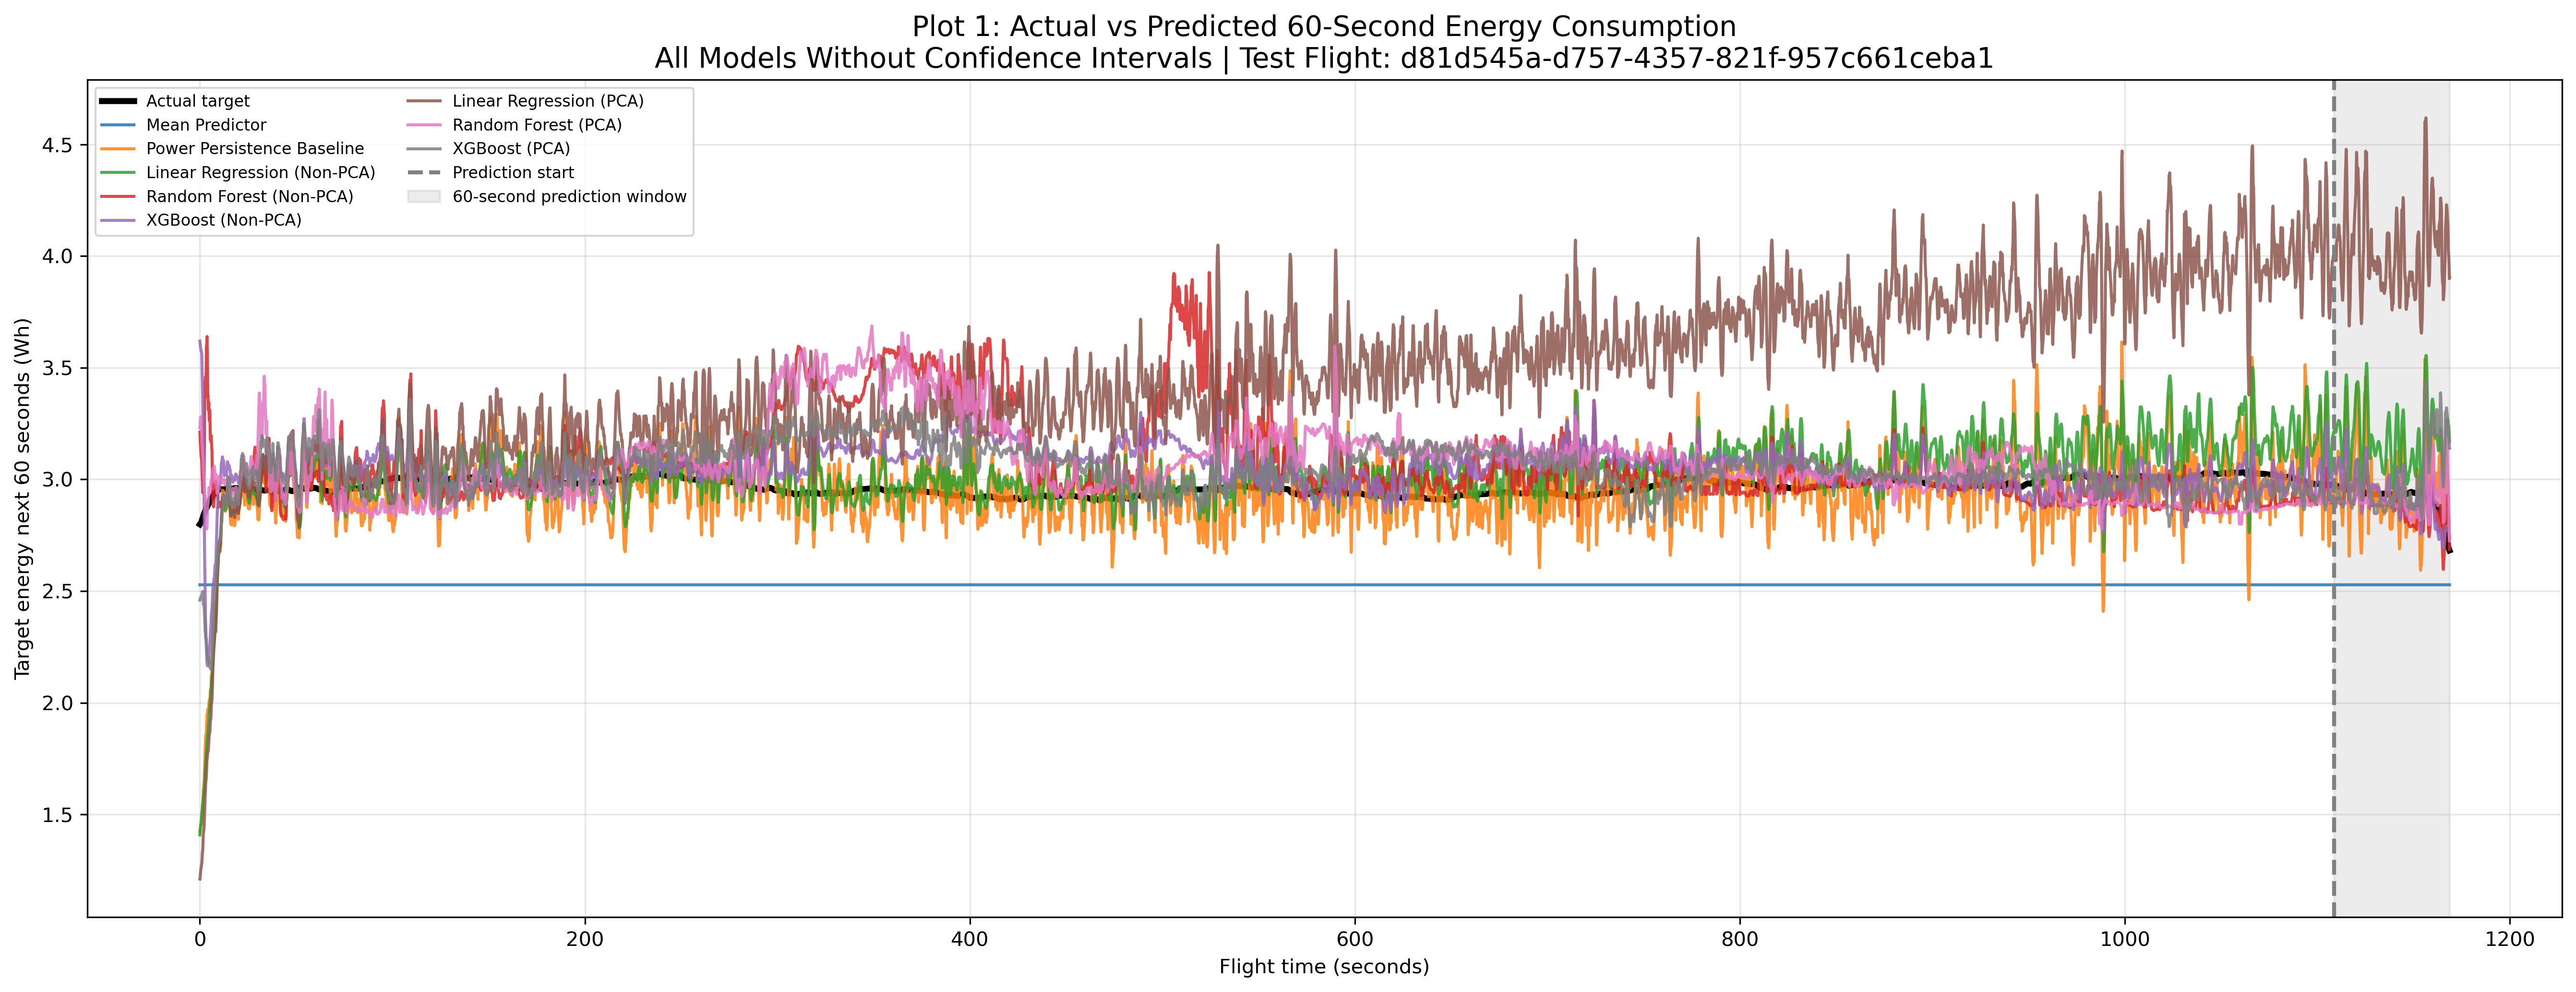

Plot saved to: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/baseline_models/plots/plot1_all_models_no_interval_d81d545a-d757-4357-821f-957c661ceba1.png


In [84]:
# ============================================================
# Plot 1: All models without confidence interval
# ============================================================

def plot_all_models_no_interval(plot_df, log_id, smooth_points=15):
    """
    Shows all model predictions in one plot without confidence intervals.
    This is cleaner than showing all uncertainty bands together.
    """

    model_cols = [
        col for col in plot_df.columns
        if col not in ["log_id", "time_s", "actual"]
        and not col.endswith("_lower")
        and not col.endswith("_upper")
    ]

    window_start, window_end = get_prediction_window(
        plot_df,
        prediction_window_seconds=60
    )

    plt.figure(figsize=(18, 7))

    # Actual target
    plt.plot(
        plot_df["time_s"],
        smooth_series(plot_df["actual"], smooth_points),
        linewidth=3,
        color="black",
        label="Actual target"
    )

    # All model predictions
    for model_name in model_cols:
        plt.plot(
            plot_df["time_s"],
            smooth_series(plot_df[model_name], smooth_points),
            linewidth=1.5,
            alpha=0.85,
            label=model_name
        )

    # 60-second prediction window
    plt.axvline(
        window_start,
        linestyle="--",
        linewidth=2,
        color="grey",
        label="Prediction start"
    )

    plt.axvspan(
        window_start,
        window_end,
        color="grey",
        alpha=0.15,
        label="60-second prediction window"
    )

    plt.title(
        f"Plot 1: Actual vs Predicted 60-Second Energy Consumption\n"
        f"All Models Without Confidence Intervals | Test Flight: {log_id}",
        fontsize=14
    )

    plt.xlabel("Flight time (seconds)")
    plt.ylabel("Target energy next 60 seconds (Wh)")
    plt.grid(True, alpha=0.3)
    plt.legend(loc="upper left", fontsize=8, ncol=2)
    plt.tight_layout()

    save_path = PLOT_DIR / f"plot1_all_models_no_interval_{log_id}.png"
    save_and_display_plot(save_path)


plot_all_models_no_interval(
    plot_df=plot_df,
    log_id=selected_log_id,
    smooth_points=15
)

## Plot 2: Best 3 models with confidence interval

Best 3 models selected for Plot 2:
- Linear Regression (Non-PCA)
- XGBoost (Non-PCA)
- Power Persistence Baseline


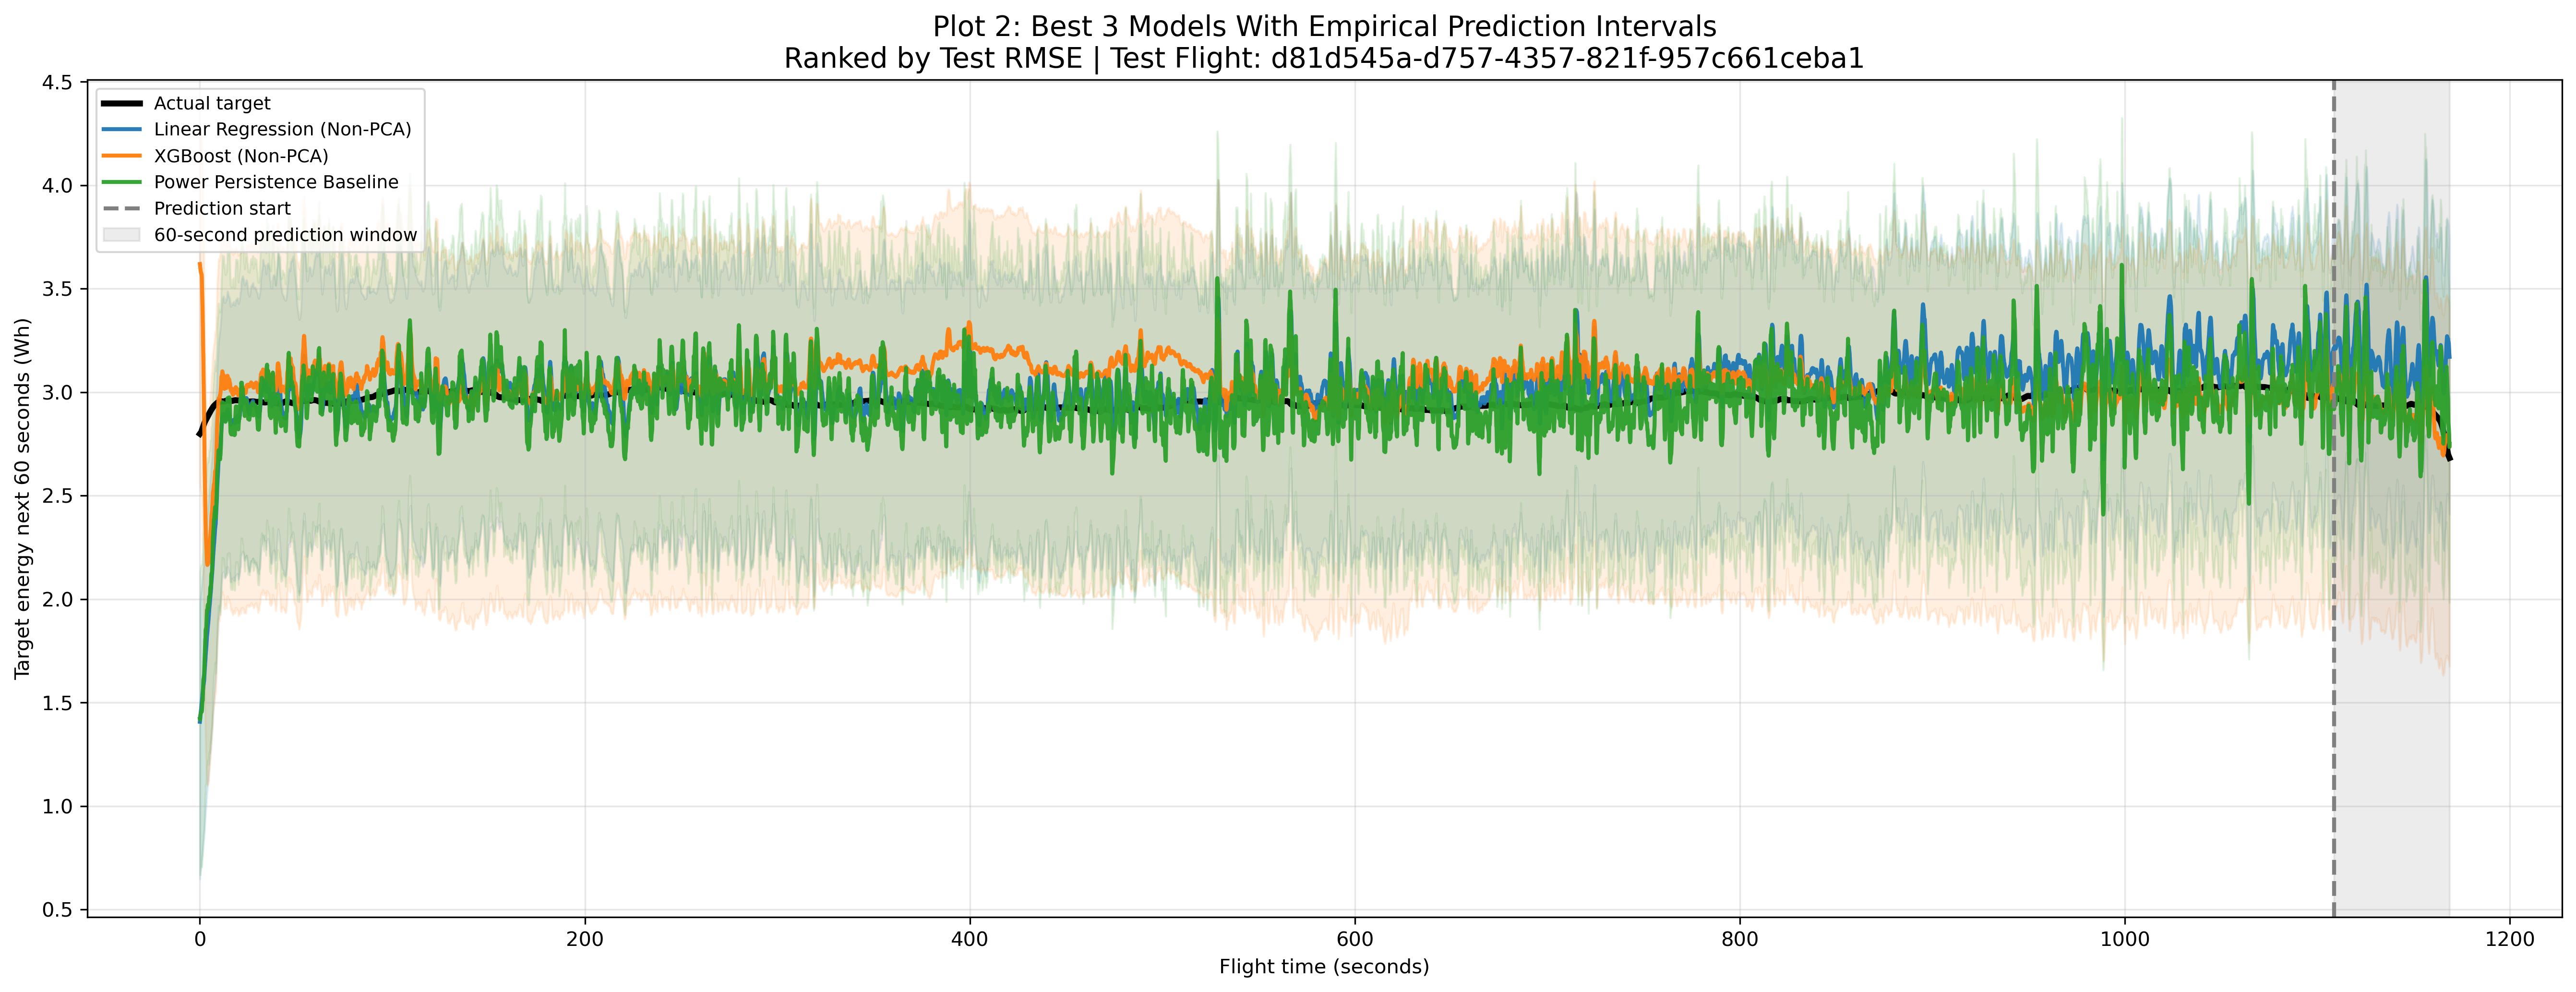

Plot saved to: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/baseline_models/plots/plot2_best3_with_interval_d81d545a-d757-4357-821f-957c661ceba1.png


In [85]:
# ============================================================
# Plot 2: Best 3 models with empirical prediction interval
# ============================================================

def get_best_3_model_names(results_df_sorted):
    """
    Selects the best 3 models based on test RMSE.
    Mean Predictor is excluded because it is only a weak sanity baseline.
    """

    temp = results_df_sorted.copy()

    # Remove duplicate Mean Predictor PCA row
    temp = temp[
        ~(
            (temp["model"] == "Mean Predictor") &
            (temp["dataset"] == "pca_features")
        )
    ].copy()

    # Exclude Mean Predictor from best 3
    temp = temp[temp["model"] != "Mean Predictor"].copy()

    temp = temp.sort_values("test_RMSE", ascending=True)

    best_names = []

    for _, row in temp.iterrows():

        model_name = row["model"]
        dataset_name = row["dataset"]

        if model_name == "Power Persistence Baseline":
            display_name = "Power Persistence Baseline"
        else:
            readable_dataset = "PCA" if dataset_name == "pca_features" else "Non-PCA"
            display_name = f"{model_name} ({readable_dataset})"

        if display_name in all_prediction_outputs:
            best_names.append(display_name)

        if len(best_names) == 3:
            break

    return best_names


def plot_best_3_with_interval(plot_df, log_id, best_model_names, smooth_points=15):
    """
    Shows only the best 3 models with empirical 90% prediction intervals.
    """

    window_start, window_end = get_prediction_window(
        plot_df,
        prediction_window_seconds=60
    )

    plt.figure(figsize=(18, 7))

    # Actual target
    plt.plot(
        plot_df["time_s"],
        smooth_series(plot_df["actual"], smooth_points),
        linewidth=3,
        color="black",
        label="Actual target"
    )

    # Best 3 models with intervals
    for model_name in best_model_names:
        line = plt.plot(
            plot_df["time_s"],
            smooth_series(plot_df[model_name], smooth_points),
            linewidth=2,
            alpha=0.95,
            label=model_name
        )[0]

        plt.fill_between(
            plot_df["time_s"],
            smooth_series(plot_df[f"{model_name}_lower"], smooth_points),
            smooth_series(plot_df[f"{model_name}_upper"], smooth_points),
            alpha=0.12,
            color=line.get_color()
        )

    # 60-second prediction window
    plt.axvline(
        window_start,
        linestyle="--",
        linewidth=2,
        color="grey",
        label="Prediction start"
    )

    plt.axvspan(
        window_start,
        window_end,
        color="grey",
        alpha=0.15,
        label="60-second prediction window"
    )

    plt.title(
        f"Plot 2: Best 3 Models With Empirical Prediction Intervals\n"
        f"Ranked by Test RMSE | Test Flight: {log_id}",
        fontsize=14
    )

    plt.xlabel("Flight time (seconds)")
    plt.ylabel("Target energy next 60 seconds (Wh)")
    plt.grid(True, alpha=0.3)
    plt.legend(loc="upper left", fontsize=9)
    plt.tight_layout()

    save_path = PLOT_DIR / f"plot2_best3_with_interval_{log_id}.png"
    save_and_display_plot(save_path)


best_3_model_names = get_best_3_model_names(results_df_sorted)

print("Best 3 models selected for Plot 2:")
for name in best_3_model_names:
    print("-", name)

plot_best_3_with_interval(
    plot_df=plot_df,
    log_id=selected_log_id,
    best_model_names=best_3_model_names,
    smooth_points=15
)

##  Plot 3: Zoomed 60-second prediction window

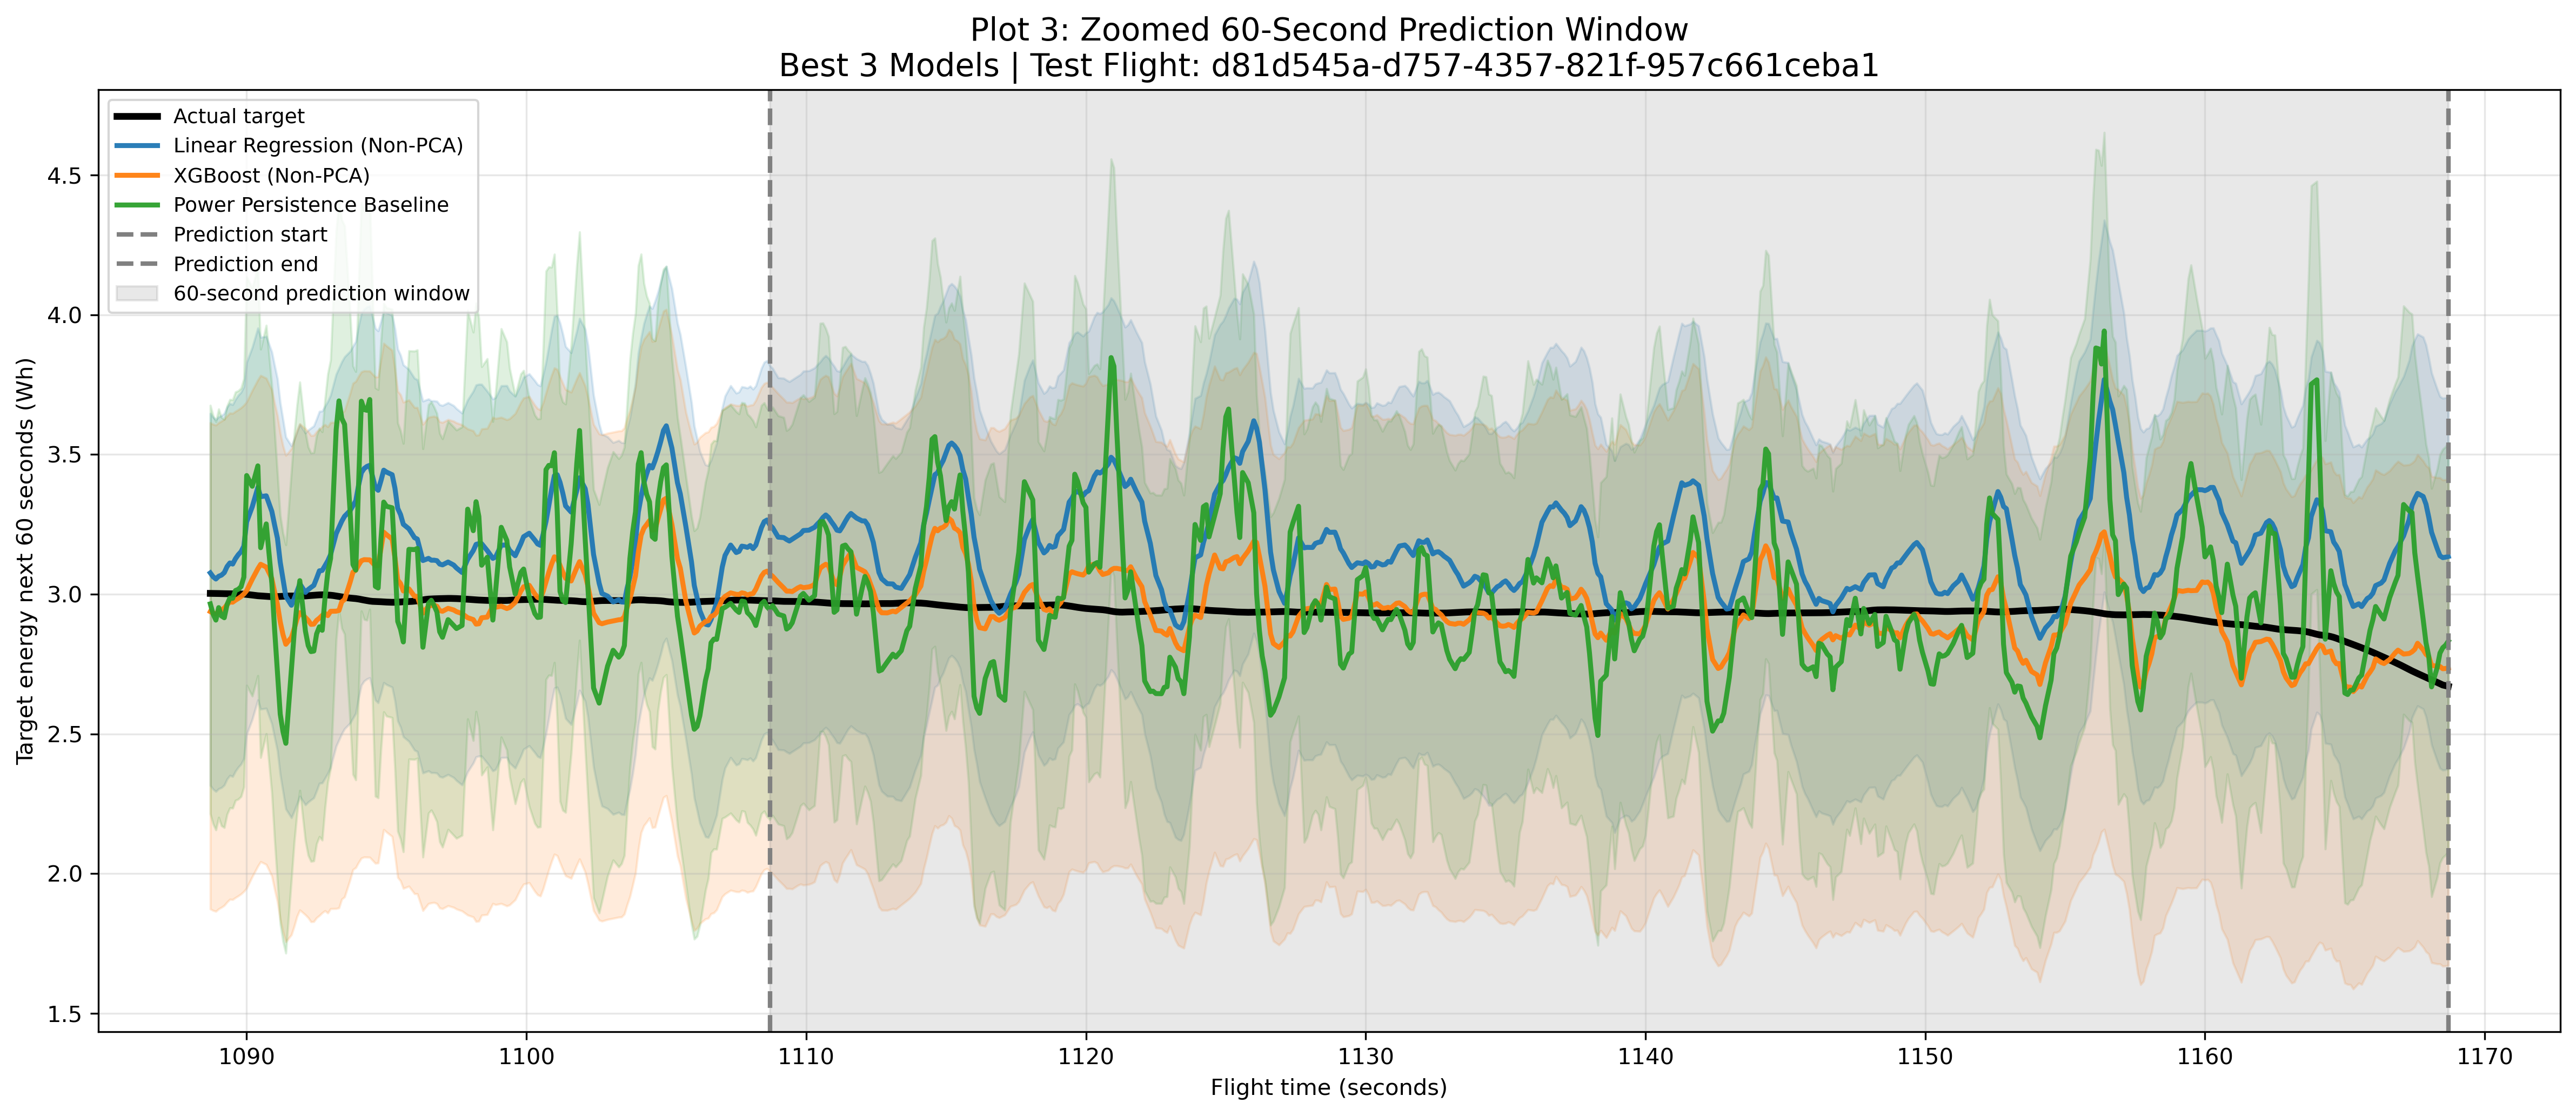

Plot saved to: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/baseline_models/plots/plot3_zoomed_60s_prediction_window_d81d545a-d757-4357-821f-957c661ceba1.png


In [86]:
# ============================================================
# Plot 3: Zoomed 60-second prediction window
# ============================================================

def plot_zoomed_prediction_window(plot_df, log_id, best_model_names, smooth_points=5):
    """
    Zooms into the selected 60-second prediction window.
    This makes the prediction behaviour easier to inspect.
    """

    window_start, window_end = get_prediction_window(
        plot_df,
        prediction_window_seconds=60
    )

    # Add small margin around the 60-second window
    zoom_start = max(plot_df["time_s"].min(), window_start - 20)
    zoom_end = min(plot_df["time_s"].max(), window_end + 20)

    zoom_df = plot_df[
        (plot_df["time_s"] >= zoom_start) &
        (plot_df["time_s"] <= zoom_end)
    ].copy()

    plt.figure(figsize=(16, 7))

    # Actual target
    plt.plot(
        zoom_df["time_s"],
        smooth_series(zoom_df["actual"], smooth_points),
        linewidth=3,
        color="black",
        label="Actual target"
    )

    # Best 3 models with intervals
    for model_name in best_model_names:
        line = plt.plot(
            zoom_df["time_s"],
            smooth_series(zoom_df[model_name], smooth_points),
            linewidth=2.2,
            alpha=0.95,
            label=model_name
        )[0]

        plt.fill_between(
            zoom_df["time_s"],
            smooth_series(zoom_df[f"{model_name}_lower"], smooth_points),
            smooth_series(zoom_df[f"{model_name}_upper"], smooth_points),
            alpha=0.15,
            color=line.get_color()
        )

    # Highlight exact 60-second window
    plt.axvline(
        window_start,
        linestyle="--",
        linewidth=2,
        color="grey",
        label="Prediction start"
    )

    plt.axvline(
        window_end,
        linestyle="--",
        linewidth=2,
        color="grey",
        label="Prediction end"
    )

    plt.axvspan(
        window_start,
        window_end,
        color="grey",
        alpha=0.18,
        label="60-second prediction window"
    )

    plt.title(
        f"Plot 3: Zoomed 60-Second Prediction Window\n"
        f"Best 3 Models | Test Flight: {log_id}",
        fontsize=14
    )

    plt.xlabel("Flight time (seconds)")
    plt.ylabel("Target energy next 60 seconds (Wh)")
    plt.grid(True, alpha=0.3)
    plt.legend(loc="upper left", fontsize=9)
    plt.tight_layout()

    save_path = PLOT_DIR / f"plot3_zoomed_60s_prediction_window_{log_id}.png"
    save_and_display_plot(save_path)


plot_zoomed_prediction_window(
    plot_df=plot_df,
    log_id=selected_log_id,
    best_model_names=best_3_model_names,
    smooth_points=5
)

n_estimators is simply the number of trees in the forest, and the current default is 100. So using 200 means you are using more trees than the default to make the prediction more stable. Random Forest usually becomes more stable as the number of trees increases. Breiman’s original Random Forest paper explains that the generalisation error converges as the number of trees becomes large.

500+ trees = possibly better, but slower

XGBoost learns differently from Random Forest. Random Forest trees are independent, but XGBoost builds trees one after another, where each new tree corrects previous errors. Chen and Guestrin introduced XGBoost as a scalable tree boosting system used for strong predictive performance on structured data.

lower learning rate usually needs more trees.



In [74]:
def evaluate_model(
    model_name,
    dataset_name,
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    test_df=None
):
    """
    Train a model and calculate validation, test, normal/abnormal,
    UAV-specific, and flight-level performance metrics.
    """

    print(f"\n{'='*60}")
    print(f"  Training : {model_name}  |  Dataset : {dataset_name}")
    print(f"{'='*60}")

    # Train model
    model.fit(X_train, y_train)

    # Predict validation and test sets
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    # Overall metrics
    results = {
        "dataset": dataset_name,
        "model": model_name,

        "val_MAE": mean_absolute_error(y_val, val_pred),
        "val_RMSE": rmse(y_val, val_pred),
        "val_R2": r2_score(y_val, val_pred),

        "test_MAE": mean_absolute_error(y_test, test_pred),
        "test_RMSE": rmse(y_test, test_pred),
        "test_R2": r2_score(y_test, test_pred),
    }

    # Add UAV-specific metrics
    results = add_uav_error_metrics(
        result=results,
        y_true=y_test,
        y_pred=test_pred
    )

    # Normal and abnormal test performance
    if test_df is not None:
        for label in ["normal", "abnormal"]:
            mask = test_df["dataset_label"].values == label

            if mask.sum() == 0:
                continue

            y_true_label = y_test.values[mask]
            y_pred_label = test_pred[mask]

            results[f"test_MAE_{label}"] = mean_absolute_error(
                y_true_label,
                y_pred_label
            )

            results[f"test_RMSE_{label}"] = rmse(
                y_true_label,
                y_pred_label
            )

            results[f"test_R2_{label}"] = r2_score(
                y_true_label,
                y_pred_label
            )

            print(
                f"  [{label:8s}]  "
                f"MAE={results[f'test_MAE_{label}']:.4f}  "
                f"RMSE={results[f'test_RMSE_{label}']:.4f}  "
                f"R²={results[f'test_R2_{label}']:.4f}"
            )

    # Flight-level MAE
    if test_df is not None and "log_id" in test_df.columns:
        flight_errors = test_df[["log_id"]].copy()

        flight_errors["absolute_error"] = np.abs(
            y_test.values - test_pred
        )

        flight_mae = (
            flight_errors
            .groupby("log_id")["absolute_error"]
            .mean()
        )

        results["test_flight_MAE_mean"] = flight_mae.mean()
        results["test_flight_MAE_median"] = flight_mae.median()

        print(
            f"  [flight]   "
            f"mean MAE={results['test_flight_MAE_mean']:.4f}  "
            f"median MAE={results['test_flight_MAE_median']:.4f}"
        )

    print(
        f"  [overall]  "
        f"test MAE={results['test_MAE']:.4f}  "
        f"RMSE={results['test_RMSE']:.4f}  "
        f"R²={results['test_R2']:.4f}"
    )

    print(
        f"  [UAV risk] "
        f"P95 error={results['test_P95_abs_error']:.4f}  "
        f"Underprediction={results['test_underprediction_rate']*100:.2f}%"
    )

    return results, model, test_pred

In [ ]:

simple_table = results_df_sorted.copy()


simple_table = simple_table[
    ~(
        (simple_table["model"] == "Mean Predictor") &
        (simple_table["dataset"] == "pca_features")
    )
].copy()



simple_table["Dataset"] = simple_table["dataset"].replace({
    "non_pca_features": "Non-PCA",
    "pca_features": "PCA"
})



simple_table["Type"] = simple_table["model_group"].replace({
    "baseline": "Baseline",
    "trained_model": "Trained model"
})


simple_table.loc[
    simple_table["model"] == "Mean Predictor",
    "Dataset"
] = "Both"



selected_cols = [
    "Type",
    "Dataset",
    "model",
    "test_MAE",
    "test_RMSE",
    "test_R2",
    "test_P95_abs_error",
    "test_underprediction_rate",
    "test_mean_underprediction_error",
    "test_flight_MAE_median"
]


selected_cols = [col for col in selected_cols if col in simple_table.columns]

simple_table = simple_table[selected_cols].copy()



simple_table = simple_table.rename(columns={
    "model": "Model",
    "test_MAE": "Test MAE",
    "test_RMSE": "Test RMSE",
    "test_R2": "Test R²",
    "test_P95_abs_error": "P95 absolute error",
    "test_underprediction_rate": "Underprediction rate",
    "test_mean_underprediction_error": "Mean underprediction error",
    "test_flight_MAE_median": "Flight median MAE"
})


# Sort models by Test RMSE
# Lower RMSE is better because it penalises large errors
simple_table = simple_table.sort_values(
    "Test RMSE",
    ascending=True
).reset_index(drop=True)


# Add ranking column
simple_table.insert(
    0,
    "Rank",
    range(1, len(simple_table) + 1)
)


# Convert underprediction rate to percentage if it exists
if "Underprediction rate" in simple_table.columns:
    simple_table["Underprediction rate"] = simple_table["Underprediction rate"] * 100


# Round numeric columns
numeric_cols = [
    "Test MAE",
    "Test RMSE",
    "Test R²",
    "P95 absolute error",
    "Underprediction rate",
    "Mean underprediction error",
    "Flight median MAE"
]

numeric_cols = [col for col in numeric_cols if col in simple_table.columns]

simple_table[numeric_cols] = simple_table[numeric_cols].round(3)


# Display final simplified table
display(simple_table)


# Save final simplified table
simple_table.to_csv(
    OUTPUT_DIR / "simplified_model_comparison_table.csv",
    index=False
)

print("Simplified model comparison table saved.")






,Rank,Type,Dataset,Model,Test MAE,Test RMSE,Test R²,P95 absolute error,Underprediction rate,Mean underprediction error,Flight median MAE
0,1,Trained model,Non-PCA,Linear Regression,0.321,0.794,0.821,NaN,NaN,NaN,0.215
1,2,Trained model,Non-PCA,XGBoost,0.324,0.852,0.794,NaN,NaN,NaN,0.155
2,3,Baseline,Non-PCA,Power Persistence Baseline,0.360,0.861,0.790,1.263,54.640,0.358,0.295
3,4,Trained model,Non-PCA,Random Forest,0.339,0.865,0.788,NaN,NaN,NaN,0.176
4,5,Trained model,PCA,XGBoost,0.398,0.937,0.751,NaN,NaN,NaN,0.199
5,6,Trained model,PCA,Random Forest,0.414,0.942,0.748,NaN,NaN,NaN,0.261
6,7,Trained model,PCA,Linear Regression,0.609,1.074,0.673,NaN,NaN,NaN,0.426
7,8,Baseline,Both,Mean Predictor,1.511,1.974,-0.104,2.528,41.491,1.092,1.380


Simplified model comparison table saved.


## 9. Save models

In [76]:
for name, model in trained_models.items():
    safe_name = name.lower().replace(" ", "_").replace("/", "_")
    joblib.dump(model, OUTPUT_DIR / f"{safe_name}.joblib")
    print(f"Saved: {safe_name}.joblib")

print("\nAll models saved.")

Saved: non_pca_features__linear_regression.joblib
Saved: non_pca_features__random_forest.joblib
Saved: non_pca_features__xgboost.joblib
Saved: pca_features__linear_regression.joblib
Saved: pca_features__random_forest.joblib
Saved: pca_features__xgboost.joblib

All models saved.


## 10. Summary 

In [77]:

print("FINAL MODEL COMPARISON SUMMARY")
print("="*70)

# Show best model based on test RMSE
best_model = results_df_sorted.iloc[0]

print("\nBest overall model:")
print(f"Model   : {best_model['model']}")
print(f"Dataset : {best_model['dataset']}")
print(f"Test MAE: {best_model['test_MAE']:.4f}")
print(f"Test RMSE: {best_model['test_RMSE']:.4f}")
print(f"Test R² : {best_model['test_R2']:.4f}")

print("\nMain result table:")
display(simple_table)

print("\nFiles saved:")
print(f"Plots   : {PLOT_DIR}")
print(f"Results : {OUTPUT_DIR}")

print("="*70)

FINAL MODEL COMPARISON SUMMARY

Best overall model:
Model   : Linear Regression
Dataset : non_pca_features
Test MAE: 0.3208
Test RMSE: 0.7944
Test R² : 0.8212

Main result table:


,Rank,Type,Dataset,Model,Test MAE,Test RMSE,Test R²,P95 absolute error,Underprediction rate,Mean underprediction error,Flight median MAE
0,1,Trained model,Non-PCA,Linear Regression,0.321,0.794,0.821,NaN,NaN,NaN,0.215
1,2,Trained model,Non-PCA,XGBoost,0.324,0.852,0.794,NaN,NaN,NaN,0.155
2,3,Baseline,Non-PCA,Power Persistence Baseline,0.360,0.861,0.790,1.263,54.640,0.358,0.295
3,4,Trained model,Non-PCA,Random Forest,0.339,0.865,0.788,NaN,NaN,NaN,0.176
4,5,Trained model,PCA,XGBoost,0.398,0.937,0.751,NaN,NaN,NaN,0.199
5,6,Trained model,PCA,Random Forest,0.414,0.942,0.748,NaN,NaN,NaN,0.261
6,7,Trained model,PCA,Linear Regression,0.609,1.074,0.673,NaN,NaN,NaN,0.426
7,8,Baseline,Both,Mean Predictor,1.511,1.974,-0.104,2.528,41.491,1.092,1.380



Files saved:
Plots   : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/baseline_models/plots
Results : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/baseline_models
